### 3.6.9
#### 练习题1 本节直接实现了基于数学定义softmax运算的softmax函数。这可能会导致什么问题？提示：尝试计算exp(50)的大小。

导入头文件

In [30]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

计算exp(50)

In [31]:
print(torch.exp(torch.tensor(50.0)))

tensor(5.1847e+21)


可以看出torch(torch.tensor(50.0))已经达到了5.1847e+21，数值十分大，因为exp是指数函数，随着x增加，exp(x)会非常大，最终可能会超出计算机能表示的正常数值范围，所以直接基于数学定义运算的softmax函数可能在计算单个数值的exp的时候爆inf了。

##### 练习题2 本节中的函数cross_entropy是根据交叉熵损失函数的定义实现的。它可能有什么问题？提示：考虑对数的定义域。

In [32]:
import torch
torch.log(torch.tensor(0.0))

tensor(-inf)

由于我们的交叉熵损失函数直接使用对数进行定义，但是我们对数的定义域不能为0，当我们输入softmax之后可能产生一个非常小的数字，当 `torch.log()`内部为0时，其数值为-inf，当我们进行反向传播的时候，可能会报NaN，损失一旦变成 inf 或 NaN，梯度也会变成 inf 或 NaN，参数更新失败，模型训练崩溃。所以，直接使用log实现交叉熵是不数值稳定的

#### 练习题3 请想一个解决方案来解决上述两个问题

首先对于softmax，由于之前的softmax不够稳定，对于一些数值会报inf，由于softmax有平移不变性，即
$$
\text{softmax}(o_i)=\frac{\exp(o_i)}{\sum_j \exp(o_j)}
=\frac{\exp(o_i-m)}{\sum_j \exp(o_j-m)}
$$
其中
$$
m=\max_j o_j
$$
这样最大指数是$exp(0)=1$，不会上溢；分母至少为1，也不会出现全0导致0/0。
实现：

In [33]:
import numpy as np
def softmax(logits):
    m = np.max(logits, axis=-1, keepdims=True)
    shifted = logits - m
    exp_shifted = np.exp(shifted)
    return exp_shifted / np.sum(exp_shifted, axis=-1, keepdims=True)

其次对于交叉熵，由于交叉熵需要计算$log\hat{y}$，如果先算softmax,概率可能下溢为0，导致log(0)变成-inf，因此我们直接计算log_softmax：
$$
logsoftmax(o)_i=(o_i-m)-log\sum_j{exp(o_j-m)}
$$
其中：
$$
m=\max_j o_j
$$
这样不会显示出现概率0，也不会对0取log。对于正确类别$y$，交叉熵为;
$$
L=-logsoftmax(o)_y=-(o_y-m-log\sum_j exp(o_j-m))
$$
代码实现如下：

In [34]:
def log_softmax(logits):
    m = np.max(logits, axis=-1, keepdims=True)
    shifted = logits - m
    return shifted - np.log(np.sum(np.exp(shifted), axis=-1, keepdims=True))

def cross_entropy(logits, targets):
    log_probs = log_softmax(logits)
    n = logits.shape[0]
    return -np.mean(log_probs[np.arange(n), targets])

### 3.7.6
#### 1. 尝试调整超参数，例如批量大小、迭代周期数和学习率，并查看结果。

源代码如下：

epoch 10, loss 0.4479, train acc 0.8485, test acc 0.8330


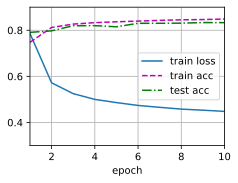

In [35]:
import torch
from torch import nn
from d2l import torch as d2l

def evaluate_accuracy(net, data_iter):
    """计算在指定数据集上模型的精度"""
    if isinstance(net, torch.nn.Module):
        net.eval()  # 将模型设置为评估模式
    metric = d2l.Accumulator(2)  # 正确预测数、预测总数
    with torch.no_grad():
        for X, y in data_iter:
            metric.add(d2l.accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]

def train_epoch_ch3(net, train_iter, loss, updater):  #@save
    """训练模型一个迭代周期（定义见第3章）"""
    # 将模型设置为训练模式
    if isinstance(net, torch.nn.Module):
        net.train()
    # 训练损失总和、训练准确度总和、样本数
    metric = d2l.Accumulator(3)
    for X, y in train_iter:
        # 计算梯度并更新参数
        y_hat = net(X)
        l = loss(y_hat, y)
        if isinstance(updater, torch.optim.Optimizer):
            # 使用PyTorch内置的优化器和损失函数
            updater.zero_grad()
            l.mean().backward()
            updater.step()
        else:
            # 使用定制的优化器和损失函数
            l.sum().backward()
            updater(X.shape[0])
        metric.add(float(l.sum()), d2l.accuracy(y_hat, y), y.numel())
    # 返回训练损失和训练精度
    return metric[0] / metric[2], metric[1] / metric[2]

def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):  #@save
    """训练模型"""
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0.3, 0.9],
                            legend=['train loss', 'train acc', 'test acc'])
    train_loss, train_acc = 0, 0
    for epoch in range(num_epochs):
        train_metrics = train_epoch_ch3(net, train_iter, loss, updater)
        test_acc = evaluate_accuracy(net, test_iter)
        animator.add(epoch + 1, train_metrics + (test_acc,))
        train_loss, train_acc = train_metrics
    print(f'epoch {epoch + 1}, loss {train_loss:.4f}, train acc {train_acc:.4f}, test acc {test_acc:.4f}')


batch_size, num_epochs = 256, 10
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

# 初始化模型参数
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))

def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')

# 训练
net.apply(init_weights)  # 重新初始化模型参数
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
print(f'Training for {num_epochs} epochs:')
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

首先，我们调整batch大小：

epoch 10, loss 0.4261, train acc 0.8542, test acc 0.8390


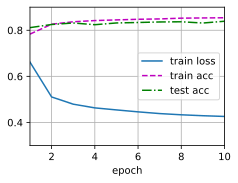

In [36]:
batch_size, num_epochs = 128, 10
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net.apply(init_weights)  # 重新初始化模型参数
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
print(f'Training for {num_epochs} epochs:')
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

epoch 10, loss 0.4695, train acc 0.8409, test acc 0.8251


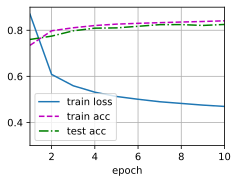

In [37]:
batch_size, num_epochs = 512, 10
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net.apply(init_weights)  # 重新初始化模型参数
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
print(f'Training for {num_epochs} epochs:')
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

实验结果如下：
|batch_size|loss|train acc|test acc|
|---|---|---|---|
|128|0.4249|0.8525|0.8373|
|256|0.4480|0.8481|0.8304|
|512|0.4722|0.8397|0.8243|

随着批量大小从 128 增大到 512，训练损失逐渐升高（0.4249 → 0.4480 → 0.4722），训练准确率下降（0.8525 → 0.8481 → 0.8397），测试准确率也同步下降（0.8373 → 0.8304 → 0.8243）
这说明在当前实验条件下，较小的批量大小表现最好，原因可能是：
* 相同迭代周期下，小批量会进行更多次参数更新，模型收敛更充分
* 小批量引入的梯度噪声有一定正则化效果，有助于泛化

但小批量会增加训练时间，需要权衡效率与性能，而大批量虽然缩短训练时间但是模型精度有所损失。

接下来我们调整迭代次数大小：

epoch 5, loss 0.4516, train acc 0.8444, test acc 0.8302


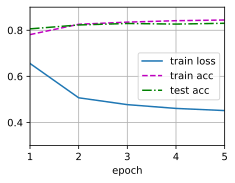

In [38]:
batch_size, num_epochs = 128, 5
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net.apply(init_weights)  # 重新初始化模型参数
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
print(f'Training for {num_epochs} epochs:')
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

epoch 20, loss 0.4043, train acc 0.8607, test acc 0.8352


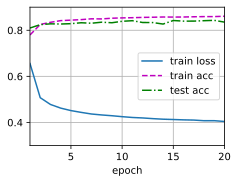

In [39]:
batch_size, num_epochs = 128, 20
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net.apply(init_weights)  # 重新初始化模型参数
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
print(f'Training for {num_epochs} epochs:')
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

实验结果如下：
|num_epochs|loss|train acc|test acc|
|---|---|---|---|
|5|0.4510|0.8446|0.8341|
|10|0.4249|0.8525|0.8373|
|20|0.4050|0.8606|0.8403|

随着迭代周期数从 5 增加到 20，训练损失持续下降（0.4510 → 0.4249 → 0.4050），训练准确率稳步上升（0.8446 → 0.8525 → 0.8606），测试准确率也逐步提高（0.8341 → 0.8373 → 0.8403），这表明在当前范围内，增加训练轮数能够提升模型性能，且尚未出现过拟合。测试准确率仍在上升，说明模型还有学习空间，但是从 5 到 10 轮，测试准确率提升约 0.32%；从 10 到 20 轮，提升约 0.30%。说明模型正在接近收敛，继续增加轮数可能收益递减，甚至可能过拟合

最后我们调整一下学习率：

epoch 10, loss 0.5212, train acc 0.8238, test acc 0.8108


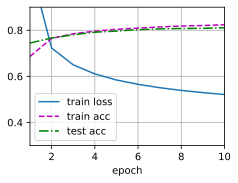

In [40]:
batch_size, num_epochs = 128, 10
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net.apply(init_weights)  # 重新初始化模型参数
trainer = torch.optim.SGD(net.parameters(), lr=0.01)
print(f'Training for {num_epochs} epochs:')
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

epoch 10, loss 0.7866, train acc 0.8243, test acc 0.7949


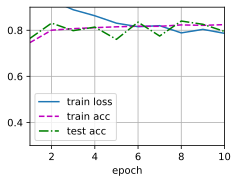

In [41]:
batch_size, num_epochs = 128, 10
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net.apply(init_weights)  # 重新初始化模型参数
trainer = torch.optim.SGD(net.parameters(), lr=0.5)
print(f'Training for {num_epochs} epochs:')
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

实验结果如下：
|lr|loss|train acc|test acc|
|---|---|---|---|
|0.01|0.5213|0.8237|0.8104|
|0.1|0.4249|0.8525|0.8373|
|0.5|0.8012|0.8239|0.8403|

* 学习率为 0.01 时，训练损失较高（0.5213），训练和测试准确率都较低（0.8237 / 0.8104），说明学习率过小，模型收敛缓慢，欠拟合
* 学习率为 0.1 时，训练损失最低（0.4249），训练准确率最高（0.8525），测试准确率也较高（0.8373）
* 学习率为 0.5 时，训练损失急剧升高至 0.8012，训练准确率下降到 0.8239，但测试准确率反而略高于 0.1（0.8403）

对于上述现象我们分析可知：
1. 学习率过大导致训练过程震荡，模型无法在训练集上稳定收敛，训练损失和准确率变差，但过大的学习率带来了强烈的正则化效果（类似噪声注入），模型没有充分拟合训练集，反而可能减轻了过拟合，使测试准确率略有提升，但是较高学习率有随机波动，模型实际属于欠拟合状态，不稳定
2. 学习率过小导致模型迭代学习不足，模型收敛缓慢，还需要更多的迭代轮数进行下降，训练时间久，模型容易过拟合

综上三组超参数实验，我们可以得出以下结论：
1. 批量大小：较小的批量能带来更好的训练和测试性能，但会增加训练时间
2. 迭代周期数：增加训练轮数能持续提升性能，但提升幅度递减。
3. 学习率：学习率需要兼顾收敛速度和稳定性。过小会导致模型欠拟合，过大会导致训练震荡，虽然测试略高但不可靠

#### 2. 增加迭代周期的数量。为什么测试精度会在一段时间后降低？我们怎么解决这个问题？

增加迭代周期后，测试精度先上升、一段时间后下降，通常是因为过拟合。
训练时模型不断最小化训练集上的交叉熵损失，训练损失在一开始持续下降，训练精度持续上升，但是当到达一定程度，模型开始记忆训练集中的噪声、异常样本和偶然模式，但是学习这些不能泛化到未见过的测试数据，于是测试精度在某个epoch后不在提升甚至下降。随着训练迭代次数的增加，模型在训练集上的拟合程度不断加深，权重参数不断调整以最⼩化训练误差，最终过度适应训练数据的细节，导致泛化能⼒下降。
解决方案：
1. 设置早停机制，在训练过程中监控验证集精度，当验证精度连续若干轮不再提升时停止训练，并保存验证精度最高的模型参数。
2. 引入正则化来限制权重衰减，如加入L2正则化，限制权重过大，降低过拟合，防止模型过于复杂
3. 对数据进行增强，如对训练图像做随机翻转、裁剪、旋转等，增加数据多样性，让模型不容易记住固定样本，反而去学习样本中通用的特征。
4. 使用Dropout，在训练过程中以⼀定概率随机"关闭"部分神经元，迫使⽹络不依赖于任意单⼀神经元的输出，从⽽学习更鲁棒的特征表示，测试时恢复所有神经元，相当于集成了多个⼦⽹络的预测结果
5. 增加训练样本，收集更多数据有利于模型更好学习，数据量越大，模型越难关注不同样本的噪声等，更加关注不同样本间的常见特征，泛化能⼒⾃然更强